# Классификация тональности отзывов IMDB — 2. Бейзлайн и отбор токенов

Данные, очистка и разбиение — те же, что в `eda.ipynb` (`core.data`): train / test = 80 / 20, стратифицированно, `random_state=34`. Тест используется только для финальной оценки, гиперпараметры подбираются на валидации, выделенной из train.

**Метрики** (функция шаблона `evaluate_classification`): accuracy, F1 (macro), precision, recall, ROC-AUC. Классы сбалансированы, поэтому основная метрика — F1, ROC-AUC — дополнительная (качество ранжирования без привязки к порогу).

Результаты всех моделей собираются в реестр `MultipleModelsResults` и сохраняются в `results/baseline_results.csv` — итоговое сравнение в `neural_networks.ipynb`.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from core.data import SEED, load_imdb, split_imdb, split_validation
from core.utils import init_random_seed, get_device
import core.visualization as p

init_random_seed(SEED)
sns.set_theme(style="whitegrid")

import time
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer, HashingVectorizer, ENGLISH_STOP_WORDS
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score
from sklearn.pipeline import make_pipeline
from lightgbm import LGBMClassifier

from core.baseline_training import fit_evaluate_sklearn, evaluate_probas
from core.training_results import MultipleModelsResults
from core.nlp import SENTIMENT_KEEP_WORDS

df = load_imdb()
X_train, X_test, y_train, y_test = split_imdb(df)
print("train:", len(X_train), "| test:", len(X_test), "| доля positive:", round(y_train.mean(), 4), round(y_test.mean(), 4))

results = MultipleModelsResults()

всего: 50000 (min слов: 4) | без дубликатов: 49582 | после фильтра >= 10 слов: 49577 (min слов: 10)
train: 39661 | test: 9916 | доля positive: 0.5019 0.5019


## 1. Бейзлайн: Count / TF-IDF / Hashing + LogisticRegression

In [2]:
vectorizers = {
    "Count": CountVectorizer(min_df=5, max_features=20000),
    "TF-IDF": TfidfVectorizer(min_df=5, max_features=20000),
    "Hashing": HashingVectorizer(n_features=2**20, alternate_sign=False),
}
for name, vec in vectorizers.items():
    fit_evaluate_sklearn(results, f"Baseline: {name} + LogReg", "1. Бейзлайн",
                         make_pipeline(vec, LogisticRegression(max_iter=1000)), X_train, y_train, X_test, y_test)

Baseline: Count + LogReg                                acc=0.8807  f1=0.8807  roc_auc=0.9464


Baseline: TF-IDF + LogReg                               acc=0.8962  f1=0.8962  roc_auc=0.9611


Baseline: Hashing + LogReg                              acc=0.8731  f1=0.8731  roc_auc=0.9444


TF-IDF лучше «сырых» счётчиков (F1 0.896 против 0.881): он снижает вес частых неинформативных слов. HashingVectorizer без IDF-взвешивания и с коллизиями хуже всех (0.873), зато не хранит словарь (полезно для потоковых данных).

### Другие классификаторы на признаках TF-IDF

Как в шаблоне, сравним несколько алгоритмов на одном векторизаторе: наивный Байес, случайный лес и градиентный бустинг (LightGBM).

In [3]:
classifiers = {
    "MultinomialNB": MultinomialNB(),
    "RandomForest": RandomForestClassifier(n_estimators=300, min_samples_leaf=2, n_jobs=-1, random_state=SEED),
    "LightGBM": LGBMClassifier(n_estimators=600, learning_rate=0.1, num_leaves=63, colsample_bytree=0.3,
                               random_state=SEED, verbose=-1),
}
for name, clf in classifiers.items():
    fit_evaluate_sklearn(results, f"Baseline: TF-IDF + {name}", "1. Бейзлайн",
                         make_pipeline(TfidfVectorizer(min_df=5, max_features=20000), clf),
                         X_train, y_train, X_test, y_test)

Baseline: TF-IDF + MultinomialNB                        acc=0.8588  f1=0.8588  roc_auc=0.9335


Baseline: TF-IDF + RandomForest                         acc=0.8509  f1=0.8509  roc_auc=0.9260


Baseline: TF-IDF + LightGBM                             acc=0.8925  f1=0.8925  roc_auc=0.9576


Логистическая регрессия остаётся лучшей. LightGBM почти догоняет её (0.893), но обучается в ~7 раз дольше. Наивный Байес (0.859) и особенно случайный лес (0.851) заметно хуже: на 20 000 разреженных признаков каждое дерево видит малую часть сигнала, а тональность складывается из многих слабых признаков, что хорошо описывает линейная модель. Дальше в экспериментах с токенами используем LogReg.

## 2. Улучшение: отбор токенов

Пробуем по очереди:
1. **Стоп-слова.** Стандартный список sklearn содержит отрицания (*not, no, nor, never…*), которые для тональности критичны (EDA), — сравним его со «щадящим» списком без отрицаний и усилителей.
2. **Порог частоты** (`min_df`, `max_df`) и **сублинейный TF**.
3. **N-граммы** (1–2): биграммы ловят отрицания и устойчивые выражения (*not good, waste of, must see*).
4. **Отбор k лучших признаков по χ²** из большого словаря n-грамм.

In [4]:
SOFT_STOP_WORDS = sorted(ENGLISH_STOP_WORDS - SENTIMENT_KEEP_WORDS)

experiments = {
    "TF-IDF + стоп-слова sklearn": TfidfVectorizer(min_df=5, max_features=20000, stop_words="english"),
    "TF-IDF + стоп-слова без отрицаний": TfidfVectorizer(min_df=5, max_features=20000, stop_words=SOFT_STOP_WORDS),
    "TF-IDF min_df=3, max_df=0.9, sublinear_tf": TfidfVectorizer(min_df=3, max_df=0.9, sublinear_tf=True),
    "TF-IDF 1-2-граммы": TfidfVectorizer(min_df=3, max_df=0.9, sublinear_tf=True, ngram_range=(1, 2)),
}
for name, vec in experiments.items():
    fit_evaluate_sklearn(results, name, "2. Отбор токенов", make_pipeline(vec, LogisticRegression(max_iter=1000)),
                         X_train, y_train, X_test, y_test)

TF-IDF + стоп-слова sklearn                             acc=0.8920  f1=0.8920  roc_auc=0.9582


TF-IDF + стоп-слова без отрицаний                       acc=0.8942  f1=0.8942  roc_auc=0.9594


TF-IDF min_df=3, max_df=0.9, sublinear_tf               acc=0.8995  f1=0.8994  roc_auc=0.9624


TF-IDF 1-2-граммы                                       acc=0.9056  f1=0.9056  roc_auc=0.9672


- Удаление стоп-слов **не помогает**: полный список sklearn снижает F1 до 0.892 (пропадают *not*, *no*, *but*), щадящий список без отрицаний — до 0.894. Оба ниже бейзлайна (0.896): для тональности даже служебные слова несут сигнал.
- Снятие ограничения `max_features` + `min_df=3`, `max_df=0.9`, `sublinear_tf` (log(1+tf)) дают прирост до 0.899.
- Биграммы дают самый большой скачок — 0.906, но словарь вырастает до ~370 тыс. признаков. Отберём из него самые информативные по критерию χ² и заодно подберём регуляризацию `C`.

размер словаря 1-2-грамм (train-часть): 330927


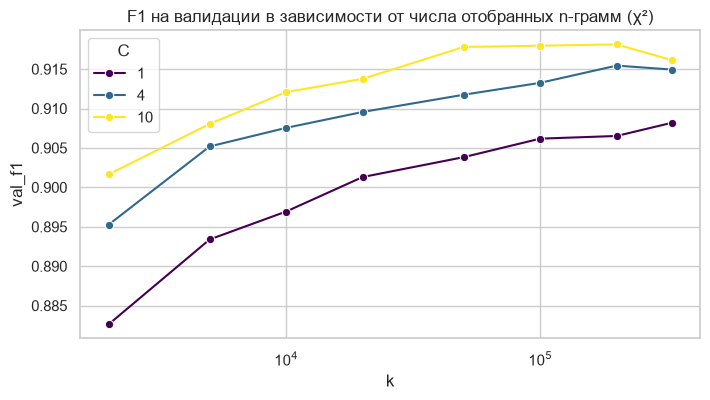

k         200000.000000
k_frac         0.604363
C             10.000000
val_f1         0.918133
Name: 20, dtype: float64

In [5]:
# k и C подбираем на валидационной части train, чтобы не подглядывать в тест.
# Векторизатор для подбора обучаем только на train-части, чтобы словарь и IDF не «видели» валидацию.
X_tr, X_val, y_tr, y_val = split_validation(X_train, y_train, val_size=0.15)
sel_vec = TfidfVectorizer(min_df=3, max_df=0.9, sublinear_tf=True, ngram_range=(1, 2))
Xs_tr, Xs_val = sel_vec.fit_transform(X_tr), sel_vec.transform(X_val)
n_feat = Xs_tr.shape[1]
print("размер словаря 1-2-грамм (train-часть):", n_feat)

rows = []
for k in [2000, 5000, 10000, 20000, 50000, 100000, 200000, n_feat]:
    k = min(k, n_feat)
    sel = SelectKBest(chi2, k=k).fit(Xs_tr, y_tr)
    for C in [1, 4, 10]:
        clf = LogisticRegression(C=C, max_iter=2000).fit(sel.transform(Xs_tr), y_tr)
        rows.append({"k": k, "k_frac": k / n_feat, "C": C,
                     "val_f1": f1_score(y_val, clf.predict(sel.transform(Xs_val)), average="macro")})
chi_df = pd.DataFrame(rows).drop_duplicates(subset=["k", "C"])

plt.figure(figsize=(8, 4))
sns.lineplot(data=chi_df, x="k", y="val_f1", hue="C", marker="o", palette="viridis")
plt.xscale("log")
plt.title("F1 на валидации в зависимости от числа отобранных n-грамм (χ²)")
plt.show()
best = chi_df.loc[chi_df["val_f1"].idxmax()]
del Xs_tr, Xs_val, sel_vec, sel, clf   # матрицы подбора больше не нужны
best

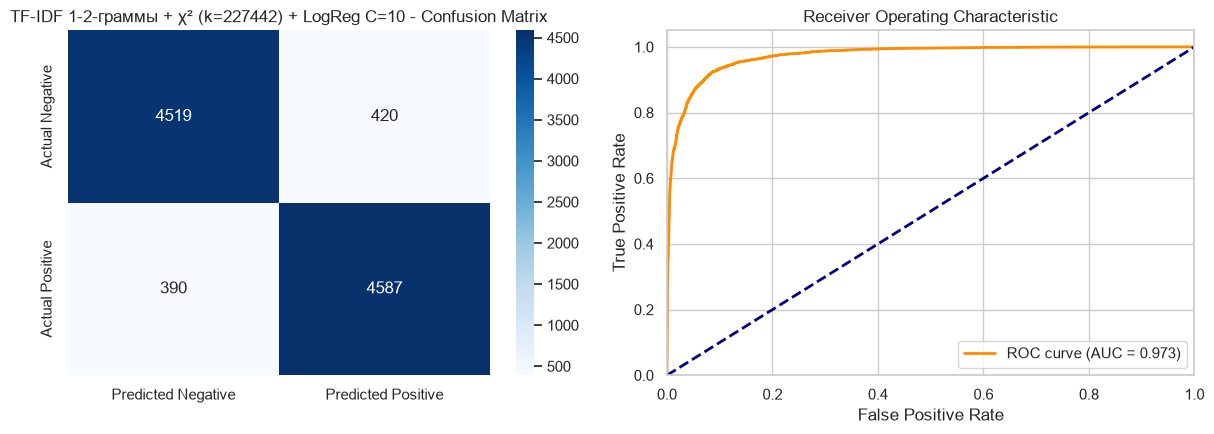


 TF-IDF 1-2-ГРАММЫ + Χ² (K=227442) + LOGREG C=10 EVALUATION 

MAIN METRICS:
   Metric  Value
  ROC AUC 0.9731
 F1 Score 0.9183
Precision 0.9183
   Recall 0.9183
 Accuracy 0.9183


CLASSIFICATION REPORT:
   Class  Precision   Recall
Positive   0.916117 0.921640
Negative   0.920554 0.914963

TF-IDF 1-2-граммы + χ² (k=227442) + LogReg C=10         acc=0.9183  f1=0.9183  roc_auc=0.9731


In [6]:
# Финальная модель: векторизатор + χ² + LogReg на всём train. Долю k переносим с подбора (словарь на полном train чуть больше).
best_C = float(best["C"])
t0 = time.time()
ngram_vec = TfidfVectorizer(min_df=3, max_df=0.9, sublinear_tf=True, ngram_range=(1, 2))
Xtr_ng, Xte_ng = ngram_vec.fit_transform(X_train), ngram_vec.transform(X_test)
best_k = int(round(best["k_frac"] * Xtr_ng.shape[1]))
selector = SelectKBest(chi2, k=best_k).fit(Xtr_ng, y_train)
best_lr = LogisticRegression(C=best_C, max_iter=2000).fit(selector.transform(Xtr_ng), y_train)
proba_best_lr = best_lr.predict_proba(selector.transform(Xte_ng))[:, 1]
BEST_LINEAR_NAME = f"TF-IDF 1-2-граммы + χ² (k={best_k}) + LogReg C={best_C:g}"
evaluate_probas(results, BEST_LINEAR_NAME, "2. Отбор токенов", y_test, proba_best_lr, time.time() - t0, enable_plot=True);

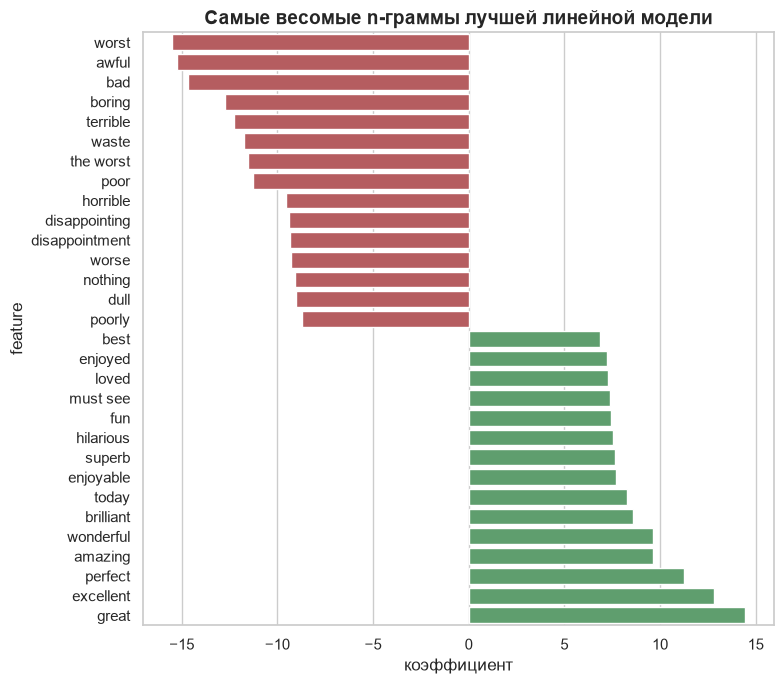

In [7]:
# Какие n-граммы модель считает самыми важными
names = ngram_vec.get_feature_names_out()[selector.get_support()]
_ = p.plot_signed_scores(names, best_lr.coef_.ravel(), "Самые весомые n-граммы лучшей линейной модели", "коэффициент")

Лучшее на валидации — оставить ~60% n-грамм (k ≈ 227 тыс. на полном train) и ослабить регуляризацию (C=10), val F1 0.918. На тесте F1 **0.918** против 0.906 у полного словаря с C=1 — это лучшая модель всего решения. Прирост складывается из двух частей: χ² выкидывает шумные редкие n-граммы, а больший C позволяет модели сильнее опираться на оставшиеся. Ошибки симметричны (420 ложноположительных, 390 ложноотрицательных). Среди самых весомых признаков — ожидаемые оценочные слова (*worst, awful, bad, boring, waste — great, excellent, perfect, amazing*) и биграммы *the worst*, *must see*.

## 3. Сохранение результатов

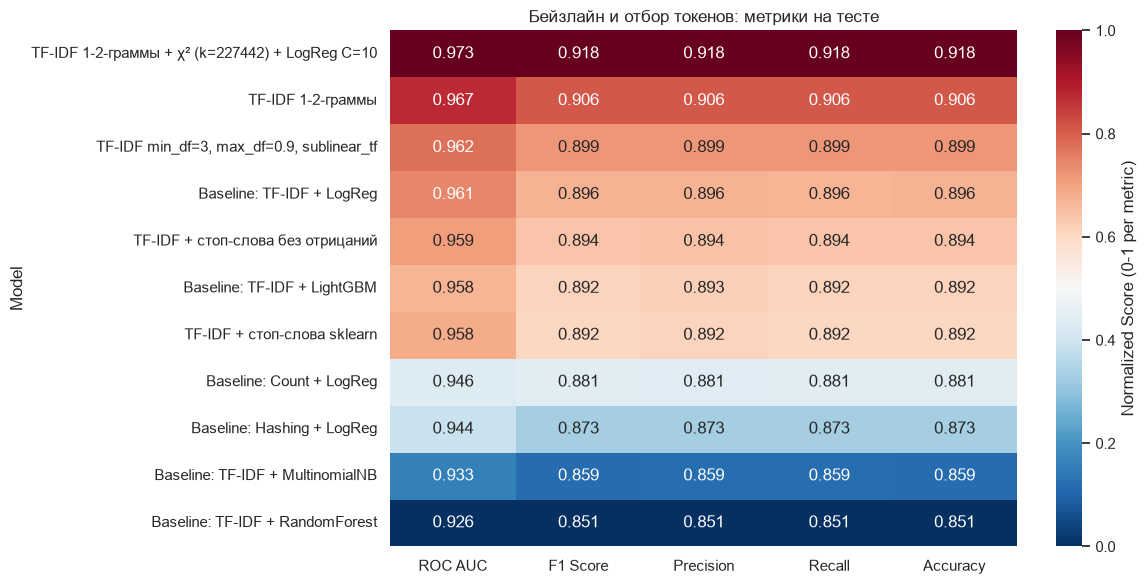

,Group,ROC AUC,F1 Score,Precision,Recall,Accuracy,Training Time (s)
Model,,,,,,,
TF-IDF 1-2-граммы + χ² (k=227442) + LogReg C=10,2. Отбор токенов,0.9731,0.9183,0.9183,0.9183,0.9183,25.6767
TF-IDF 1-2-граммы,2. Отбор токенов,0.9672,0.9056,0.9057,0.9056,0.9056,21.1399
"TF-IDF min_df=3, max_df=0.9, sublinear_tf",2. Отбор токенов,0.9624,0.8994,0.8995,0.8994,0.8995,6.7419
Baseline: TF-IDF + LogReg,1. Бейзлайн,0.9611,0.8962,0.8964,0.8962,0.8962,7.7051
TF-IDF + стоп-слова без отрицаний,2. Отбор токенов,0.9594,0.8942,0.8944,0.8942,0.8942,6.5302
Baseline: TF-IDF + LightGBM,1. Бейзлайн,0.9576,0.8925,0.8925,0.8925,0.8925,57.9068
TF-IDF + стоп-слова sklearn,2. Отбор токенов,0.9582,0.8920,0.8923,0.8919,0.8920,6.0231
Baseline: Count + LogReg,1. Бейзлайн,0.9464,0.8807,0.8807,0.8807,0.8807,21.1488
Baseline: Hashing + LogReg,1. Бейзлайн,0.9444,0.8731,0.8733,0.8731,0.8731,10.5137


In [8]:
import os
os.makedirs("results", exist_ok=True)
baseline_df = results.save_csv("results/baseline_results.csv")
# вероятности лучшей линейной модели — для анализа ошибок и сравнения с нейросетями в neural_networks.ipynb
pd.DataFrame({"y_true": y_test.values, "proba": proba_best_lr}, index=y_test.index).to_csv("results/proba_best_linear.csv")
with open("results/best_linear_name.txt", "w", encoding="utf-8") as f:
    f.write(BEST_LINEAR_NAME)
p.plot_metrics_heatmap(baseline_df.drop(columns=["Training Time (s)"]).sort_values("F1 Score", ascending=False),
                       title="Бейзлайн и отбор токенов: метрики на тесте")
baseline_df.sort_values("F1 Score", ascending=False).round(4)

## Выводы

| Эксперимент | F1 | ROC-AUC |
|---|---|---|
| Лучший бейзлайн: TF-IDF + LogReg | 0.896 | 0.961 |
| Другие классификаторы на TF-IDF (LightGBM / NB / RF) | 0.893 / 0.859 / 0.851 | 0.958 / 0.933 / 0.926 |
| TF-IDF 1-2-граммы, sublinear TF | 0.906 | 0.967 |
| **TF-IDF 1-2-граммы + χ² (k ≈ 227 тыс.) + LogReg C=10** | **0.918** | **0.973** |

1. Задача хорошо решается «мешком слов»: TF-IDF + LogReg уже дают F1 ≈ 0.90; из классификаторов лучше всех линейная модель.
2. Отбор токенов даёт **+2.2 п.п.** F1: главное — биграммы, сублинейный TF и отбор признаков по χ² с подбором регуляризации.
3. Удаление стоп-слов вредит даже в щадящем варианте.

Дальше: `neural_networks.ipynb` — нейросети, эмбеддинги, предобученные модели и итоговое сравнение.